# Chapitre 7 - Cours 1 : vue d'ensemble du finetuning et quand y recourir

Les chapitres 5 et 6 adaptaient un modèle **sans toucher à ses poids** : consignes,
exemples, contexte récupéré, outils. Le **finetuning** adapte au contraire le modèle en
**poursuivant son entraînement**, sur tout ou partie de ses paramètres. Ce premier notebook
couvre les sections *Finetuning Overview* et *When to Finetune* du chapitre 7
(sous-sections *Reasons to Finetune*, *Reasons Not to Finetune*, *Finetuning and RAG*) :

1. le finetuning, une forme d'apprentissage par transfert (expérience : transfert de
   représentations contre apprentissage de zéro, en fonction du nombre d'exemples) ;
2. les étapes de l'entraînement et les chemins d'adaptation (diagramme, formats de
   données, masque de perte d'un exemple supervisé) ;
3. les raisons de finetuner (démonstration d'un échec de **format** sur Qwen2.5-0.5B) ;
4. les raisons de ne pas finetuner (coûts, maintenance, BloombergGPT, calcul du point
   mort entre exemples dans le prompt et modèle finetuné) ;
5. finetuning ou RAG ? (échecs d'information contre échecs de comportement, données
   d'Ovadia et al., arbre de décision) ;
6. un flux de travail d'adaptation (diagramme de la démarche itérative).

Les notebooks suivants traitent des goulots mémoire et de la quantification (cours 2),
de PEFT, LoRA et QLoRA avec un vrai finetuning (cours 3), puis de la fusion de modèles et
des tactiques d'entraînement (cours 4).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

c7.setup_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 110)

## 1. Le finetuning, une forme d'apprentissage par transfert (section *Finetuning Overview*)

**Le problème.** Les tâches qui nous intéressent (classer des tickets, répondre à des
questions juridiques, écrire du SQL dans un dialecte maison) disposent rarement de
millions d'exemples annotés. Les données **abondantes**, elles, sont du texte brut.

**L'idée.** L'**apprentissage par transfert** (*transfer learning*, Bozinovski et Fulgosi,
1976) consiste à réutiliser ce qu'un modèle a appris sur une tâche riche en données pour
accélérer l'apprentissage d'une tâche voisine, comme un pianiste apprend plus vite un
second instrument. Pour un LLM, la tâche source est la complétion de texte
(pré-entraînement) ; la tâche cible est la vôtre. Le bénéfice se mesure en **efficacité
en échantillons** (*sample efficiency*) : atteindre une qualité donnée avec moins
d'exemples. Le livre cite l'ordre de grandeur : des millions d'exemples pour entraîner un
modèle juridique de zéro, quelques centaines pour finetuner un bon modèle de base.

Le livre distingue deux façons de transférer :

- le **finetuning** : on continue d'entraîner les poids du modèle ;
- le **transfert par caractéristiques** (*feature-based transfer*) : le modèle pré-entraîné
  sert d'extracteur de représentations (des embeddings), sur lesquelles on entraîne un
  petit modèle (une « tête » de classification, chapitre 2).

**Expérience.** On veut classer de courts messages de clients en quatre catégories
(livraison, facturation, technique, compte). Le module fournit 14 phrases par catégorie,
rédigées à la main avec un vocabulaire volontairement varié (`c7.PHRASES_CLASSIF`). Pour
$k$ exemples annotés par catégorie, on entraîne deux classifieurs et on les teste sur
toutes les phrases restantes :

- un classifieur appris **de zéro** sur des n-grammes de caractères (TF-IDF + régression
  logistique) : il ne sait rien de la langue au départ ;
- le même classifieur sur les **embeddings** d'un modèle pré-entraîné multilingue
  (`paraphrase-multilingual-MiniLM-L12-v2`) : transfert par caractéristiques.

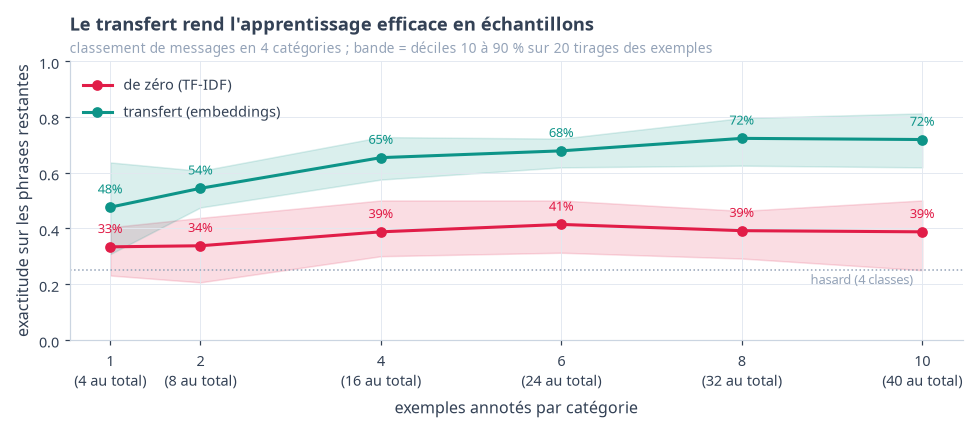

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

X_txt = [s for c in c7.CATEGORIES for s in c7.PHRASES_CLASSIF[c]]
y_all = np.array([c for c in c7.CATEGORIES for _ in c7.PHRASES_CLASSIF[c]])
E_all = llm.embed(X_txt, llm.EMBED_MULTI)

ks = [1, 2, 4, 6, 8, 10]
res = {"de zéro (TF-IDF)": [], "transfert (embeddings)": []}
for k in ks:
    accs_s, accs_t = [], []
    for rep in range(20):  # 20 tirages des exemples d'entraînement
        rng = np.random.default_rng(rep)
        idx = np.concatenate([rng.choice(np.where(y_all == c)[0], k, replace=False) for c in c7.CATEGORIES])
        te = np.setdiff1d(np.arange(len(X_txt)), idx)
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)).fit([X_txt[i] for i in idx])
        clf = LogisticRegression(max_iter=2000, C=10).fit(vec.transform([X_txt[i] for i in idx]), y_all[idx])
        accs_s.append((clf.predict(vec.transform([X_txt[i] for i in te])) == y_all[te]).mean())
        clf = LogisticRegression(max_iter=2000, C=10).fit(E_all[idx], y_all[idx])
        accs_t.append((clf.predict(E_all[te]) == y_all[te]).mean())
    res["de zéro (TF-IDF)"].append(accs_s); res["transfert (embeddings)"].append(accs_t)

fig, ax = plt.subplots(figsize=(9, 4))
for (name, a), c in zip(res.items(), [ROSE, TEAL]):
    a = np.array(a); m = a.mean(1)
    ax.plot(ks, m, "o-", color=c, label=name)
    ax.fill_between(ks, np.percentile(a, 10, 1), np.percentile(a, 90, 1), color=c, alpha=0.15)
    for kk, mm in zip(ks, m):
        ax.annotate(f"{mm:.0%}", (kk, mm), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5, color=c)
ax.axhline(0.25, color=GRAY, ls=":", lw=1); ax.text(9.9, 0.20, "hasard (4 classes)", color=GRAY, fontsize=8.5, ha="right")
ax.set_xticks(ks, [f"{k}\n({4 * k} au total)" for k in ks])
ax.set_xlabel("exemples annotés par catégorie"); ax.set_ylabel("exactitude sur les phrases restantes")
ax.set_ylim(0, 1.0); ax.legend(loc="upper left")
c7.title_sub(ax, "Le transfert rend l'apprentissage efficace en échantillons",
             "classement de messages en 4 catégories ; bande = déciles 10 à 90 % sur 20 tirages des exemples")
plt.tight_layout(); plt.show()

**Lecture.** Avec une poignée d'exemples, le modèle appris de zéro ne peut s'appuyer que
sur des morceaux de mots communs entre entraînement et test : il généralise mal à des
formulations nouvelles (« la boîte était écrasée » ne partage presque aucun n-gramme
avec « mon paquet n'est jamais arrivé ») et plafonne bien en dessous du modèle à transfert. Les embeddings pré-entraînés savent déjà que ces phrases
parlent de la même chose : quelques exemples par classe suffisent. Le finetuning d'un
LLM pousse la même logique plus loin : au lieu de figer les représentations, on les
ajuste. L'article InstructGPT (2022), cité par le livre, propose d'ailleurs de voir le
finetuning comme le moyen de **déverrouiller** des capacités que le modèle possède déjà
mais que le prompt seul n'arrive pas à faire sortir.

> **À retenir.** Le finetuning est un cas d'apprentissage par transfert : il exploite ce
> que le pré-entraînement a appris sur des données abondantes pour apprendre une tâche
> cible avec peu d'exemples. Plus le modèle de départ est proche de la tâche, moins il
> reste de travail.

## 2. Les étapes de l'entraînement et les chemins d'adaptation (section *Finetuning Overview*)

Tout entraînement qui suit le pré-entraînement est, au sens large, du finetuning. Le
livre en recense plusieurs formes, qui se distinguent surtout par **le format des
données** :

| Forme | Données | Supervision | Exemple d'usage |
|---|---|---|---|
| Pré-entraînement continu | texte brut du domaine | auto-supervisée | documents juridiques, textes en vietnamien |
| Infilling | texte avec un « trou » | auto-supervisée | édition de texte, débogage de code |
| SFT (*supervised finetuning*) | paires (instruction, réponse) | supervisée | suivi de consignes, formats |
| Finetuning de préférence | (instruction, réponse gagnante, réponse perdante) | comparaisons | alignement sur les préférences humaines |
| Contexte long | longues séquences | auto-supervisée | étendre la fenêtre (positions) |

Le **pré-entraînement continu** (*continued pre-training*) est l'étape bon marché : avant
d'investir dans des paires annotées, on familiarise le modèle avec le texte brut du
domaine. Le finetuning pour un **contexte long** est le plus délicat : il touche aux
plongements de position et peut dégrader le modèle sur les séquences courtes. Le livre
illustre ces étapes avec la famille Code Llama (Rozière et al., 2024), construite à
partir de Llama 2 ; le diagramme ci-dessous résume ces chemins.

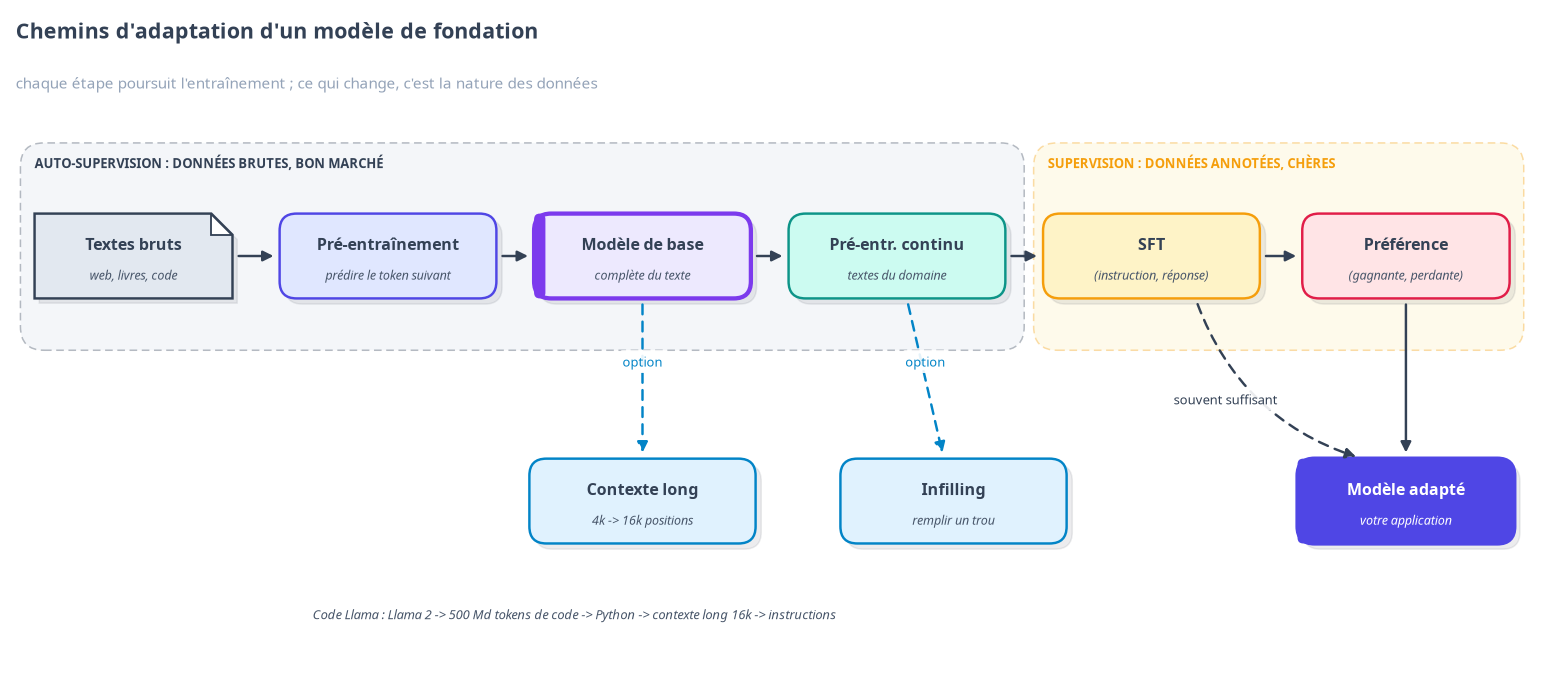

In [3]:
d = Diagram(16.2, 6.0, title="Chemins d'adaptation d'un modèle de fondation",
            subtitle="chaque étape poursuit l'entraînement ; ce qui change, c'est la nature des données")
xs = [1.3, 4.0, 6.7, 9.4, 12.1, 14.8]
d.group(0.1, 3.35, 10.75, 5.55, "auto-supervision : données brutes, bon marché", SLATE)
d.group(10.85, 3.35, 16.05, 5.55, "supervision : données annotées, chères", AMBER)
d.box("web", xs[0], 4.35, "Textes bruts", sub="web, livres, code", color=SLATE, kind="doc", w=2.1)
d.box("pt", xs[1], 4.35, "Pré-entraînement", sub="prédire le token suivant", color=INDIGO, w=2.3)
d.box("base", xs[2], 4.35, "Modèle de base", sub="complète du texte", color=VIOLET, kind="model", w=2.3)
d.box("cpt", xs[3], 4.35, "Pré-entr. continu", sub="textes du domaine", color=TEAL, w=2.3)
d.box("sft", xs[4], 4.35, "SFT", sub="(instruction, réponse)", color=AMBER, w=2.3)
d.box("pref", xs[5], 4.35, "Préférence", sub="(gagnante, perdante)", color=ROSE, w=2.2)
for a, b in [("web", "pt"), ("pt", "base"), ("base", "cpt"), ("cpt", "sft"), ("sft", "pref")]:
    d.arrow(a, b)
d.box("lc", 6.7, 1.75, "Contexte long", sub="4k -> 16k positions", color=SKY, w=2.4)
d.box("fim", 10.0, 1.75, "Infilling", sub="remplir un trou", color=SKY, w=2.4)
d.box("app", 14.8, 1.75, "Modèle adapté", sub="votre application", color=INDIGO, kind="model", w=2.3, filled=True)
d.arrow("base", "lc", "option", style="dashed", color=SKY)
d.arrow("cpt", "fim", "option", style="dashed", color=SKY)
d.arrow("pref", "app")
d.arrow("sft", "app", "souvent suffisant", style="dashed", rad=0.25, label_offset=(-0.35, 0))
d.note(3.2, 0.55, "Code Llama : Llama 2 -> 500 Md tokens de code -> Python -> contexte long 16k -> instructions",
       fontsize=8.5, ha="left")
d.show()

Le développeur d'**applications** part rarement d'un modèle de base brut : il finetune en
général un modèle déjà post-entraîné (une version « Instruct »). Plus ce point de départ
est raffiné et proche de la tâche, moins le finetuning a de travail à faire.

**Ce qu'apprend un exemple supervisé.** En SFT, chaque exemple est la concaténation d'un
prompt (au format de conversation du modèle) et de la réponse attendue. Le modèle est
entraîné à prédire chaque token à partir des précédents, mais on **pondère** la perte :
les tokens de la réponse comptent pleinement, ceux du prompt peu ou pas du tout (on y
reviendra au cours 4 avec le *prompt loss weight*). Visualisons un exemple de notre tâche
tel que le voit Qwen2.5 : en gris les tokens du prompt (poids 0), en indigo ceux de la
réponse (poids 1).

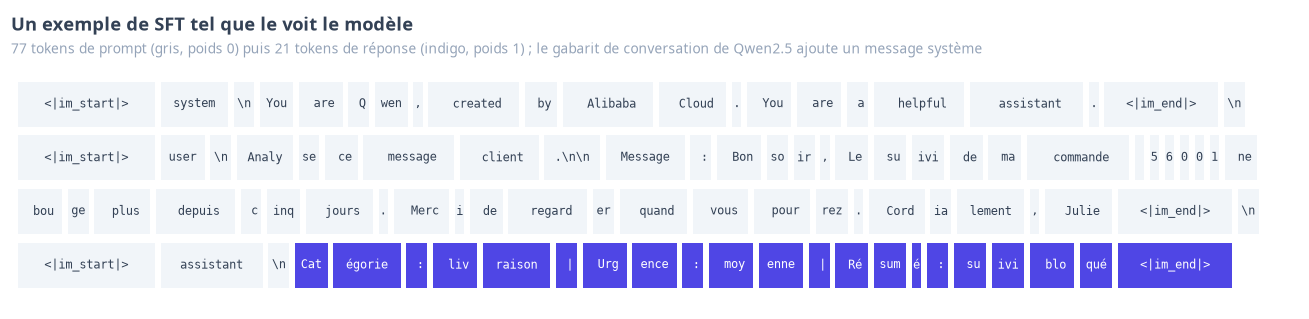

In [4]:
tok, _ = llm.load(llm.SMALL)
pool = c7.make_tickets(8, seed=0)   # tickets de la tâche fil rouge (voir cours 3)
ex = pool[0]
sft = c7.build_sft_example(tok, c7.chat_prompt(tok, c7.INSTRUCTION, ex.message), ex.cible)
toks = [tok.decode([i]) for i in sft["input_ids"]]


def draw_tokens(ax, toks, weights, width=110, max_lines=12):
    """Dessine les tokens comme des pastilles colorées selon leur poids dans la perte."""
    x, y = 0, 0
    for t, w in zip(toks, weights):
        s = t.replace("\n", "\\n")
        L = max(len(s), 1)
        if x + L > width:
            x, y = 0, y + 1
        if y >= max_lines:
            break
        col = INDIGO if w >= 1 else GRAY
        ax.add_patch(plt.Rectangle((x + 0.1, -y - 0.42), L - 0.2, 0.84, color=LIGHT[col] if w < 1 else col, lw=0))
        ax.text(x + L / 2, -y, s, ha="center", va="center", fontsize=7.6, family="DejaVu Sans Mono",
                color="white" if w >= 1 else SLATE)
        x += L + 0.3
    ax.set_xlim(-0.5, width + 0.5); ax.set_ylim(-y - 0.8, 0.8); ax.axis("off")


fig, ax = plt.subplots(figsize=(12, 3.0))
draw_tokens(ax, toks, sft["weights"])
c7.title_sub(ax, "Un exemple de SFT tel que le voit le modèle",
             f"{sft['n_prompt']} tokens de prompt (gris, poids 0) puis {len(toks) - sft['n_prompt']} tokens de réponse "
             "(indigo, poids 1) ; le gabarit de conversation de Qwen2.5 ajoute un message système")
plt.tight_layout(); plt.show()

Le prompt est beaucoup plus long que la réponse : sans masque, l'essentiel du signal
d'apprentissage porterait sur la recopie du gabarit et du message client, et non sur ce
que l'on veut enseigner (la ligne de sortie).

Pour l'**infilling**, on transforme un texte ordinaire en (préfixe, suffixe, milieu) :
le modèle voit le préfixe et le suffixe, et doit produire le milieu. C'est encore de
l'auto-supervision (aucune annotation), ce qui permet d'entraîner un modèle autorégressif
à « remplir les trous » :

In [5]:
code = "def moyenne(xs):\n    total = sum(xs)\n    return total / len(xs)\n"
a, b = code.index("total ="), code.index("\n    return")
pd.DataFrame({"partie": ["préfixe (vu)", "suffixe (vu)", "milieu (à prédire)"],
              "contenu": [repr(code[:a]), repr(code[b:]), repr(code[a:b])]})

,partie,contenu
0,préfixe (vu),'def moyenne(xs):\n '
1,suffixe (vu),'\n return total / len(xs)\n'
2,milieu (à prédire),'total = sum(xs)'


> **À retenir.** Pré-entraînement continu, infilling, SFT, préférence et contexte long sont
> tous des « finetunings » : ils diffèrent par le format des données et leur coût
> d'obtention. En SFT, on apprend surtout la **réponse** : la perte des tokens du prompt est
> réduite ou annulée.

## 3. Raisons de finetuner (section *Reasons to Finetune*)

La raison principale est la **qualité** : capacités générales ou spécifiques à une tâche.
Le livre insiste sur un usage très fréquent : faire respecter un **format ou une
structure de sortie** (JSON, YAML, dialecte SQL peu courant, DSL interne). Autres motifs
cités :

- un modèle généraliste peu exposé à votre tâche (requêtes SQL propres à un client) ;
- la **réduction de biais** par des données soigneusement choisies (par exemple
  Garimella et al., 2022, sur des modèles de type BERT) ;
- rendre **un petit modèle** compétitif : Grammarly a finetuné des Flan-T5 qui
  surpassaient une variante de GPT-3 spécialisée en édition, en étant 60 fois plus
  petits, avec 82 000 paires (instruction, sortie). La **distillation** (imiter un grand
  modèle avec des données qu'il génère) est traitée au chapitre 8.

**Démonstration d'un échec de comportement.** On demande à Qwen2.5-0.5B-Instruct
d'« analyser ce message client », sans lui décrire le format voulu. L'information
nécessaire est entièrement dans le message ; ce qui manque, c'est la **forme** attendue
(une ligne `Catégorie : ... | Urgence : ... | Résumé : ...`).

In [6]:
demo = c7.make_tickets(24, seed=2, split="test")
prompts0 = [c7.chat_prompt(tok, c7.INSTRUCTION, t.message) for t in demo]
prompts1 = [c7.chat_prompt(tok, c7.INSTRUCTION_DETAILLEE, t.message) for t in demo]
_, model = llm.load(llm.SMALL)
out0 = c7.generate_batch(model, tok, prompts0, max_new_tokens=40)
out1 = c7.generate_batch(model, tok, prompts1, max_new_tokens=40)
s0, s1 = c7.score_tickets(out0, demo), c7.score_tickets(out1, demo)
pd.DataFrame({"message": [t.message[:70] + "..." for t in demo[:3]],
              "attendu": [t.cible for t in demo[:3]],
              "consigne minimale": [o[:90].replace("\n", " ") for o in out0[:3]],
              "consigne détaillée + exemple": [o[:90].replace("\n", " ") for o in out1[:3]]})

,message,attendu,consigne minimale,consigne détaillée + exemple
0,"Bonsoir, Il manque un article dans ma commande 33544. Simple question,...",Catégorie : livraison | Urgence : basse | Résumé : article manquant,"Je suis désolé de vous faire passer cette information, mais je ne peux pas analyser ou int",Urgence : moyenne | Résumé : Article manquant dans la commande
1,"Salut, Je voudrais changer la carte bancaire de mon abonnement. Merci ...",Catégorie : facturation | Urgence : moyenne | Résumé : changement de moyen de paiement,Voici une analyse détaillée du message : 1. **Type d'objet**: Le message est un message c,Catégorie : facturation | Urgence : moyenne | Résumé : demande d'assistance pour modificat
2,"Bonjour, Le bouton de téléchargement des factures ne fait rien. Quand ...",Catégorie : technique | Urgence : basse | Résumé : bouton inactif,"Je suis désolé, mais je ne peux pas comprendre ou analyser ce message client. Je n'ai pas",Facturation | moyenne | basée


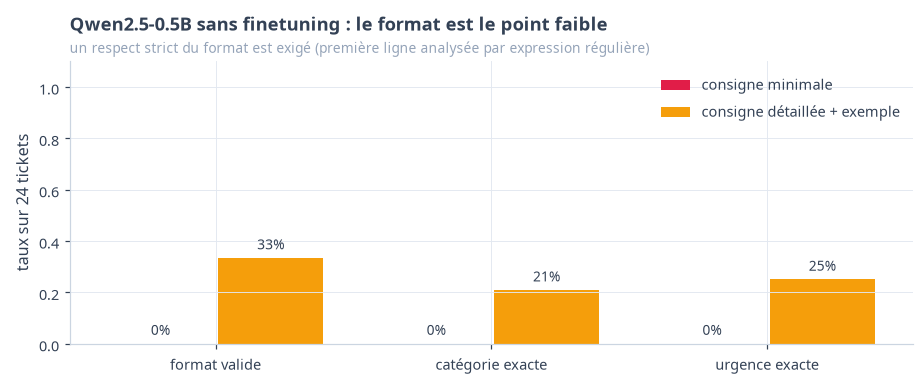

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
keys = list(s0)
xk = np.arange(len(keys))
ax.bar(xk - 0.2, [s0[k] for k in keys], 0.38, color=ROSE, label="consigne minimale")
ax.bar(xk + 0.2, [s1[k] for k in keys], 0.38, color=AMBER, label="consigne détaillée + exemple")
annotate_bars(ax, "{:.0%}")
ax.set_xticks(xk, keys); ax.set_ylim(0, 1.1); ax.set_ylabel("taux sur 24 tickets"); ax.legend()
c7.title_sub(ax, "Qwen2.5-0.5B sans finetuning : le format est le point faible",
             "un respect strict du format est exigé (première ligne analysée par expression régulière)")
plt.tight_layout(); plt.show()

Sans consigne de format, le modèle produit des analyses en prose : aucune sortie n'est
exploitable par un programme. Une consigne détaillée avec un exemple améliore nettement
les choses, mais le petit modèle reste irrégulier (champ oublié, valeurs hors liste).
C'est exactement le cas d'usage où le livre recommande d'envisager le finetuning... après
avoir **vraiment** épuisé le prompt. Au cours 3, un finetuning LoRA de quelques secondes
sur 160 exemples fera passer le format valide à 100 %.

> **À retenir.** On finetune d'abord pour la **forme** (format, style, structure) et pour
> rendre un **petit** modèle bon sur une tâche précise. Un petit modèle finetuné peut battre
> un grand modèle généraliste sur sa tâche, à coût d'inférence bien moindre.

## 4. Raisons de ne pas finetuner (section *Reasons Not to Finetune*)

Le livre dresse la liste des coûts cachés :

1. **Dégradation ailleurs.** Finetuner sur une tâche peut dégrader les autres (certains
   parlent de « taxe d'alignement »). Remèdes : finetuner sur toutes les tâches qui
   comptent, utiliser des modèles séparés, ou les **fusionner** (cours 4).
2. **Investissement initial** : des données annotées (lentes et chères, chapitre 8) et des
   compétences d'entraînement (optimiseur, taux d'apprentissage, sur-apprentissage,
   évaluation en cours de route).
3. **Service** : héberger soi-même un modèle finetuné, c'est faire de l'optimisation
   d'inférence (chapitre 9).
4. **Maintenance** : de nouveaux modèles de base sortent sans cesse et progressent
   parfois plus vite que votre version finetunée. Quand faut-il changer ?

L'encadré *Finetuning Domain-Specific Tasks* raconte l'histoire de **BloombergGPT** :
50 milliards de paramètres, 1,3 million d'heures de GPU A100, soit 1,3 à 2,6 millions de
dollars de calcul. Le même mois, GPT-4-0314, un modèle généraliste utilisé sans aucun
exemple, le dépassait largement sur des tâches financières (tableau 7-1 du livre).

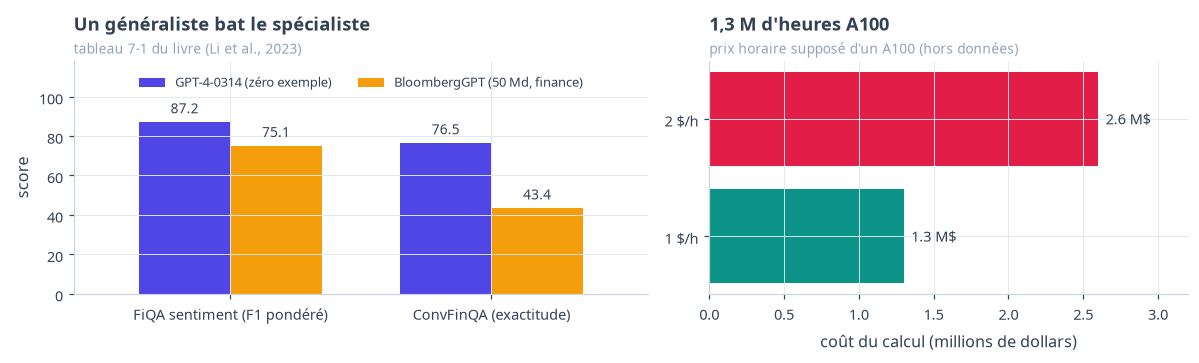

In [8]:
bb = pd.DataFrame({"FiQA sentiment (F1 pondéré)": [87.15, 75.07], "ConvFinQA (exactitude)": [76.48, 43.41]},
                  index=["GPT-4-0314 (zéro exemple)", "BloombergGPT (50 Md, finance)"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.2, 1]})
bb.T.plot.bar(ax=axes[0], color=[INDIGO, AMBER], rot=0, width=0.7)
annotate_bars(axes[0], "{:.1f}"); axes[0].set_ylabel("score")
c7.title_sub(axes[0], "Un généraliste bat le spécialiste", "tableau 7-1 du livre (Li et al., 2023)")
axes[0].set_ylim(0, 118); axes[0].legend(loc="upper center", fontsize=8.5, ncol=2)
hours = 1.3e6
prices = np.array([1.0, 2.0])
axes[1].barh(["1 $/h", "2 $/h"], hours * prices / 1e6, color=[TEAL, ROSE])
for i, v in enumerate(hours * prices / 1e6):
    axes[1].text(v + 0.05, i, f"{v:.1f} M\\$", va="center", fontsize=9.5)
axes[1].set_xlabel("coût du calcul (millions de dollars)"); axes[1].set_xlim(0, 3.2)
c7.title_sub(axes[1], "1,3 M d'heures A100", "prix horaire supposé d'un A100 (hors données)")
plt.tight_layout(); plt.show()

**Un calcul de point mort.** Un avantage historique du finetuning est d'économiser les
tokens : au lieu de mettre $k$ exemples dans chaque prompt, on les « grave » dans les
poids. Soit $n$ requêtes, $t_0$ tokens de base par prompt, $t_s$ tokens d'exemples, $t_o$
tokens de sortie, des prix $p_{in}$, $p_{out}$ par million de tokens, et un modèle
finetuné aux prix $p'_{in}, p'_{out}$ avec un coût fixe $C$ :
$$\text{few-shot}(n) = n\,\frac{(t_0 + t_s)\,p_{in} + t_o\,p_{out}}{10^6}, \qquad
  \text{finetuné}(n) = C + n\,\frac{t_0\,p'_{in} + t_o\,p'_{out}}{10^6}.$$
Le point mort est $n^\star = C\,10^6 / \big((t_0 + t_s)p_{in} + t_o p_{out} - t_0 p'_{in} - t_o p'_{out}\big)$.
Avec le **cache de prompt** (chapitre 9), les exemples répétés coûtent beaucoup moins
cher : on le modélise ici par un prix d'entrée réduit à 10 % sur la partie $t_s$
(hypothèse illustrative). Les prix ci-dessous sont des hypothèses, pas des tarifs réels.

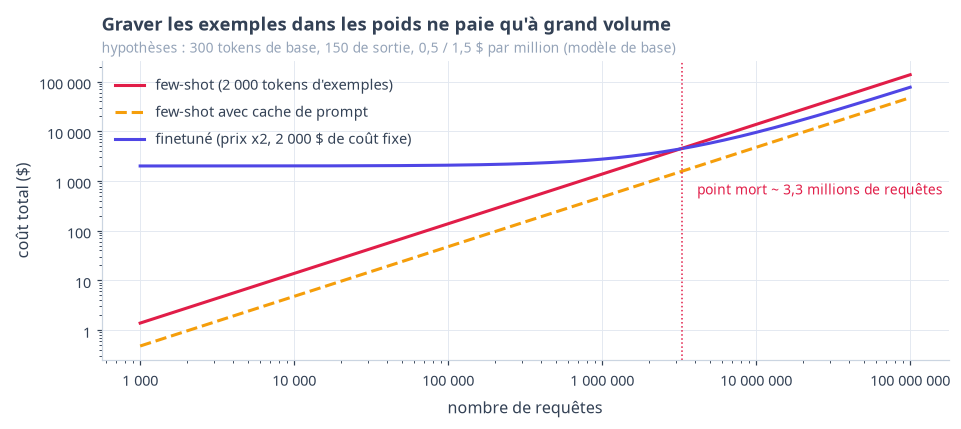

In [9]:
n = np.logspace(3, 8, 200)
hyp = dict(shot_tokens=2000, base_tokens=300, out_tokens=150, price_in=0.5, price_out=1.5)
few = c7.fewshot_vs_finetune_cost(n, **hyp)["few-shot"]
few_cache = n * ((hyp["base_tokens"] + 0.1 * hyp["shot_tokens"]) * hyp["price_in"] + hyp["out_tokens"] * hyp["price_out"]) / 1e6
ft = c7.fewshot_vs_finetune_cost(n, **hyp, ft_price_in=1.0, ft_price_out=3.0, ft_fixed_cost=2000)["finetuné"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(n, few, color=ROSE, label="few-shot (2 000 tokens d'exemples)")
ax.loglog(n, few_cache, color=AMBER, ls="--", label="few-shot avec cache de prompt")
ax.loglog(n, ft, color=INDIGO, label="finetuné (prix x2, 2 000 \\$ de coût fixe)")
for curve, c in [(few, ROSE), (few_cache, AMBER)]:
    i = np.argmax(ft < curve)
    if ft[i] < curve[i]:
        ax.axvline(n[i], color=c, ls=":", lw=1)
        ax.annotate(f"point mort ~ {n[i] / 1e6:.1f} millions de requêtes".replace(".", ","), (n[i], ft[i]),
                    xytext=(10, -30 if c == ROSE else 20), textcoords="offset points", color=c, fontsize=9)
ax.set_xlabel("nombre de requêtes"); ax.set_ylabel("coût total (\\$)")
c7.plain_log(ax, "x"); c7.plain_log(ax, "y"); ax.legend(loc="upper left")
c7.title_sub(ax, "Graver les exemples dans les poids ne paie qu'à grand volume",
             "hypothèses : 300 tokens de base, 150 de sortie, 0,5 / 1,5 \\$ par million (modèle de base)")
plt.tight_layout(); plt.show()

Le cache de prompt repousse fortement le point mort, voire le fait disparaître : c'est
pourquoi le livre note que l'économie de tokens n'est plus un argument fort. Il en reste
un : le nombre d'exemples d'un prompt est borné par la fenêtre de contexte, alors qu'un
finetuning peut en absorber autant qu'on veut.

Enfin, l'anecdote rapportée par le livre est instructive : les équipes qui « ont tout
essayé en prompt » avaient souvent fait des expériences minimales et non systématiques
(consignes floues, exemples non représentatifs, métriques mal définies). Les pratiques
rigoureuses de prompt (pipeline d'évaluation, consignes d'annotation, suivi des
expériences) sont de toute façon les fondations d'un futur finetuning.

> **À retenir.** Le finetuning coûte en données, en compétences, en service et surtout en
> **maintenance**. On commence presque toujours par le prompt ; on finetune quand des
> expériences **systématiques** de prompt ont montré leurs limites.

## 5. Finetuning ou RAG ? (section *Finetuning and RAG*)

Une fois le prompt optimisé, la question devient : RAG ou finetuning ? Le livre répond
par le **diagnostic des échecs** :

- **échecs d'information** : la réponse est fausse ou périmée parce que le modèle n'a pas
  l'information (données privées, événements postérieurs à la date de coupure). Remède :
  le **RAG** ;
- **échecs de comportement** : la réponse est correcte mais hors sujet, mal formatée,
  trop vague, ou dans une syntaxe peu connue (*semantic parsing*, DSL). Remède : le
  **finetuning**.

Formule du livre : le finetuning est pour la **forme**, le RAG pour les **faits**.
Démontrons-le avec un fait inventé (le modèle ne peut pas le connaître) et notre tâche de
format.

In [10]:
doc = ("Politique de la boutique Lumina (mise à jour 2026) : les retours sont acceptés pendant "
       "45 jours ; le remboursement est fait sous 5 jours ouvrés ; les articles soldés ne sont pas repris.")
q = "Combien de jours ai-je pour retourner un article chez Lumina ?"
r_sans = llm.chat(q, max_new_tokens=60)
r_rag = llm.chat(f"Contexte : {doc}\n\nQuestion : {q} Réponds en une phrase.", max_new_tokens=60)
fmt_rag = c7.generate_batch(model, tok, [c7.chat_prompt(tok, c7.INSTRUCTION + "\nContexte : " + doc, t.message)
                                         for t in demo[:12]], 40)
pd.DataFrame({"situation": ["fait inconnu, sans contexte", "fait inconnu, avec le document (RAG)",
                            "format, avec un document en contexte"],
              "sortie du modèle (tronquée)": [r_sans[:120], r_rag[:120], fmt_rag[0][:120].replace("\n", " ")],
              "diagnostic": ["échec d'information", "corrigé par le RAG",
                             f"format valide : {c7.score_tickets(fmt_rag, demo[:12])['format valide']:.0%} : le RAG n'aide pas"]})

,situation,sortie du modèle (tronquée),diagnostic
0,"fait inconnu, sans contexte","Je suis désolé, mais je ne peux pas vous aider avec ça.",échec d'information
1,"fait inconnu, avec le document (RAG)",Vous avez 45 jours pour retourner un article chez Lumina.,corrigé par le RAG
2,"format, avec un document en contexte","Voici une analyse détaillée du message : 1. Contexte général : - Le message est adressé à Sophie, une ...",format valide : 0% : le RAG n'aide pas


Sans le document, le modèle invente une durée ou se dérobe (vérifiez la première ligne :
le chiffre 45 ne peut venir que du contexte) ; avec le document, il le retrouve. Le RAG ne
change en revanche rien au format : ajouter des connaissances ne lui apprend pas la
**forme** attendue.

**Les données d'Ovadia et al. (2024).** Le livre rapporte (tableau 7-2) une expérience sur
des questions d'actualité : le RAG sur le modèle de base l'emporte sur toutes les variantes
finetunées, et même sur RAG + modèle finetuné. Le finetuning a amélioré une chose et en a
dégradé une autre.

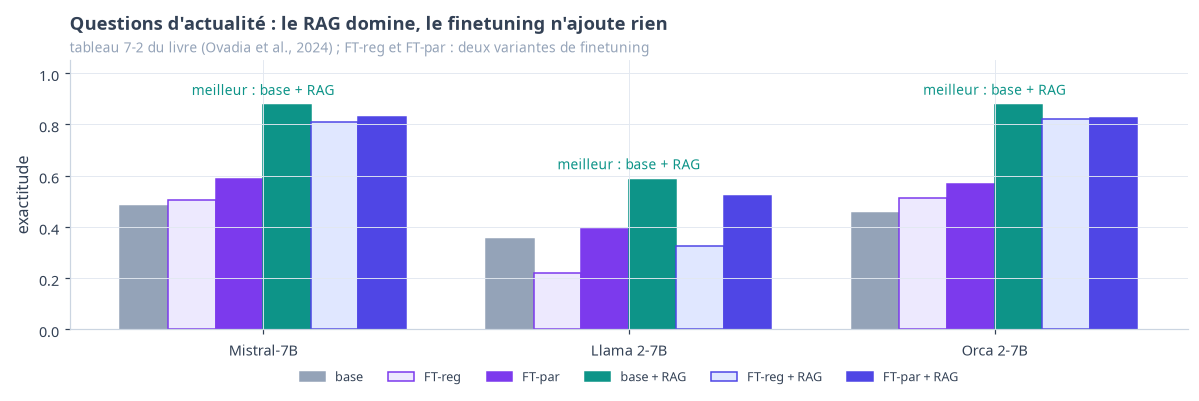

In [11]:
ov = pd.DataFrame(c7.OVADIA).T
cols = ["base", "FT-reg", "FT-par", "base + RAG", "FT-reg + RAG", "FT-par + RAG"]
colors = [GRAY, LIGHT[VIOLET], VIOLET, TEAL, LIGHT[INDIGO], INDIGO]
fig, ax = plt.subplots(figsize=(11, 3.8))
w = 0.13
for j, (c, col) in enumerate(zip(cols, colors)):
    ax.bar(np.arange(3) + (j - 2.5) * w, ov[c], w, color=col, label=c,
           edgecolor=[GRAY, VIOLET, VIOLET, TEAL, INDIGO, INDIGO][j], lw=1)
for i, m in enumerate(ov.index):
    best = ov.loc[m, cols].idxmax()
    ax.text(i, ov.loc[m, best] + 0.04, f"meilleur : {best}", ha="center", fontsize=9, color=TEAL)
ax.set_xticks(range(3), ov.index); ax.set_ylim(0, 1.05); ax.set_ylabel("exactitude")
ax.legend(ncol=6, fontsize=8.3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
c7.title_sub(ax, "Questions d'actualité : le RAG domine, le finetuning n'ajoute rien",
             "tableau 7-2 du livre (Ovadia et al., 2024) ; FT-reg et FT-par : deux variantes de finetuning")
plt.tight_layout(); plt.show()

Le livre ajoute deux nuances : RAG et finetuning ne s'excluent pas (dans la même étude,
RAG sur un modèle finetuné améliore le score MMLU dans 43 % des cas), et un finetuning sur
de bonnes données peut réduire les hallucinations, mais l'aggraver sur de mauvaises. Si
le modèle a **les deux** types de problèmes, on commence par le RAG (pas de données
d'entraînement à constituer, pas de modèle à héberger), et par un RAG simple (BM25) avant
les bases vectorielles. L'arbre de décision ci-dessous résume la démarche ; il est codé
dans `c7.recommend_adaptation`.

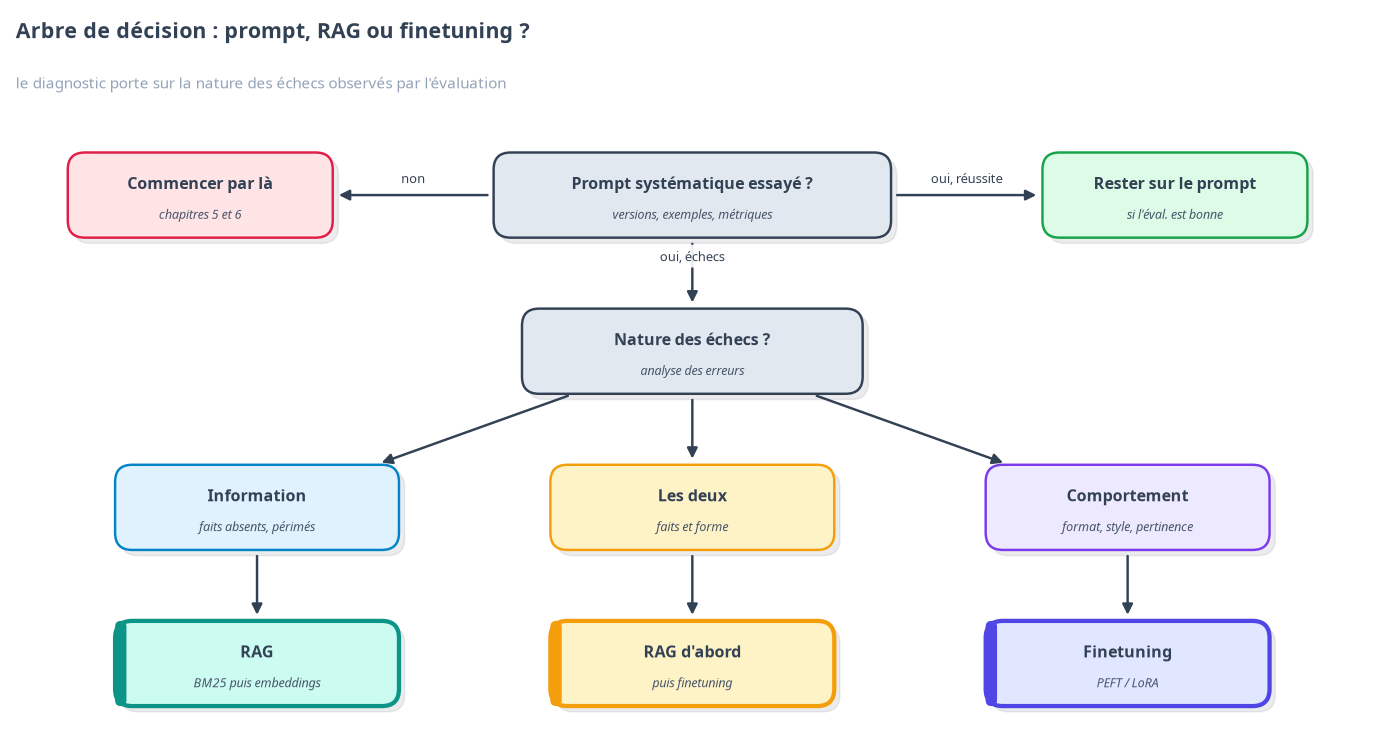

,scénario,recommandation
0,Le modèle ignore la politique interne de remboursement,RAG simple (BM25)
1,Le JSON produit est souvent invalide malgré un prompt soigné,finetuning (PEFT / LoRA)
2,Personne n'a encore écrit de prompt versionné,prompt engineering systématique (avec exemples)
3,Réponses périmées malgré un BM25 déjà en place,"RAG avancé (embeddings, hybride)"
4,"Ton inadapté et faits manquants, RAG déjà en place",RAG + finetuning
5,"Style maison à imiter, mais aucun exemple disponible",collecter des données (chapitre 8) avant de finetuner


In [12]:
d = Diagram(14.4, 6.6, title="Arbre de décision : prompt, RAG ou finetuning ?",
            subtitle="le diagnostic porte sur la nature des échecs observés par l'évaluation")
d.box("q1", 7.2, 5.6, "Prompt systématique essayé ?", sub="versions, exemples, métriques", color=SLATE, w=4.2)
d.box("no1", 2.0, 5.6, "Commencer par là", sub="chapitres 5 et 6", color=ROSE, w=2.8)
d.box("ok", 12.3, 5.6, "Rester sur le prompt", sub="si l'éval. est bonne", color=GREEN, w=2.8)
d.box("q2", 7.2, 3.95, "Nature des échecs ?", sub="analyse des erreurs", color=SLATE, w=3.6)
d.box("info", 2.6, 2.3, "Information", sub="faits absents, périmés", color=SKY, w=3.0)
d.box("both", 7.2, 2.3, "Les deux", sub="faits et forme", color=AMBER, w=3.0)
d.box("beh", 11.8, 2.3, "Comportement", sub="format, style, pertinence", color=VIOLET, w=3.0)
d.box("rag", 2.6, 0.65, "RAG", sub="BM25 puis embeddings", color=TEAL, kind="model", w=3.0)
d.box("rf", 7.2, 0.65, "RAG d'abord", sub="puis finetuning", color=AMBER, kind="model", w=3.0)
d.box("ft", 11.8, 0.65, "Finetuning", sub="PEFT / LoRA", color=INDIGO, kind="model", w=3.0)
d.arrow("q1", "no1", "non")
d.arrow("q1", "ok", "oui, réussite")
d.arrow("q1", "q2", "oui, échecs")
d.arrow("q2", "info"); d.arrow("q2", "both"); d.arrow("q2", "beh")
d.arrow("info", "rag"); d.arrow("both", "rf"); d.arrow("beh", "ft")
d.show()

scen = [("Le modèle ignore la politique interne de remboursement", True, "information", True, False),
        ("Le JSON produit est souvent invalide malgré un prompt soigné", True, "comportement", True, False),
        ("Personne n'a encore écrit de prompt versionné", False, "comportement", True, False),
        ("Réponses périmées malgré un BM25 déjà en place", True, "information", True, True),
        ("Ton inadapté et faits manquants, RAG déjà en place", True, "les deux", True, True),
        ("Style maison à imiter, mais aucun exemple disponible", True, "comportement", False, False)]
pd.DataFrame([(s, c7.recommend_adaptation(p, f, h, r)) for s, p, f, h, r in scen],
             columns=["scénario", "recommandation"])

> **À retenir.** Diagnostiquez avant de choisir : échecs d'**information** -> RAG ;
> échecs de **comportement** -> finetuning ; les deux -> RAG d'abord. Le RAG complexifie
> l'inférence (composants en plus), le finetuning complexifie le développement mais laisse
> l'inférence inchangée.

## 6. Un flux de travail d'adaptation (section *Finetuning and RAG*)

Le livre propose (figure 7-3, inspirée d'OpenAI) une progression type, en rappelant
qu'il n'existe pas de chemin universel. Le point non négociable est le **pipeline
d'évaluation**, défini avant toute adaptation (chapitre 4) et utilisé à **chaque**
étape pour savoir si l'on progresse.

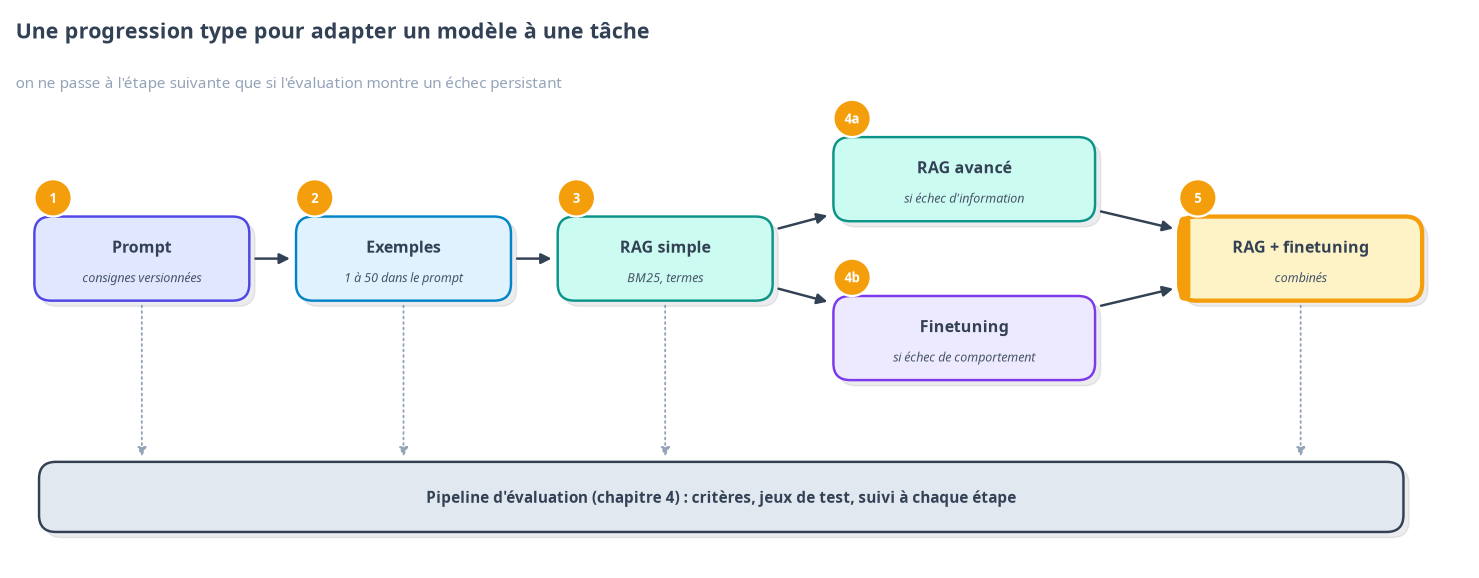

In [13]:
d = Diagram(15.6, 5.0, title="Une progression type pour adapter un modèle à une tâche",
            subtitle="on ne passe à l'étape suivante que si l'évaluation montre un échec persistant")
d.box("p", 1.4, 3.3, "Prompt", sub="consignes versionnées", color=INDIGO, w=2.3)
d.box("ex", 4.2, 3.3, "Exemples", sub="1 à 50 dans le prompt", color=SKY, w=2.3)
d.box("rag", 7.0, 3.3, "RAG simple", sub="BM25, termes", color=TEAL, w=2.3)
d.box("adv", 10.2, 4.15, "RAG avancé", sub="si échec d'information", color=TEAL, w=2.8)
d.box("ft", 10.2, 2.45, "Finetuning", sub="si échec de comportement", color=VIOLET, w=2.8)
d.box("both", 13.8, 3.3, "RAG + finetuning", sub="combinés", color=AMBER, w=2.6, kind="model")
for i, (a, b) in enumerate([("p", "ex"), ("ex", "rag")]):
    d.arrow(a, b)
d.arrow("rag", "adv"); d.arrow("rag", "ft")
d.arrow("adv", "both"); d.arrow("ft", "both")
for i, (x, y) in enumerate([(0.45, 3.95), (3.25, 3.95), (6.05, 3.95), (9.0, 4.8), (9.0, 3.1), (12.7, 3.95)]):
    d.badge(x, y, ["1", "2", "3", "4a", "4b", "5"][i])
d.box("eval", 7.6, 0.75, "Pipeline d'évaluation (chapitre 4) : critères, jeux de test, suivi à chaque étape",
      color=SLATE, w=14.6, h=0.75, fontsize=10)
for n_ in ["p", "ex", "rag", "both"]:
    d.line([(d.nodes[n_].x, d.nodes[n_].y - 0.47), (d.nodes[n_].x, 1.15)], color=GRAY, style="dotted")
d.show()

Les deux branches 4a et 4b ne pèsent pas au même endroit : le RAG avancé ajoute des
composants **à l'inférence** (index, modèle d'embeddings, latence), le finetuning ajoute
de la complexité **au développement** (données, entraînement, versionnage des modèles)
mais laisse l'inférence identique.

> **À retenir.** L'adaptation est itérative : prompt, exemples, RAG simple, puis RAG avancé
> ou finetuning selon les échecs, et enfin leur combinaison. L'évaluation accompagne
> chaque étape.

## Synthèse

- Le finetuning est une forme d'**apprentissage par transfert** : il réutilise le
  pré-entraînement pour apprendre une tâche avec peu d'exemples (efficacité en
  échantillons, mesurée en section 1).
- Il prend plusieurs formes (pré-entraînement continu, infilling, SFT, préférence,
  contexte long) qui se distinguent par le **format** et le **coût** des données. En SFT,
  on pondère la perte pour apprendre surtout la réponse.
- On finetune avant tout pour la **forme** et pour rendre un petit modèle bon sur une
  tâche ; on ne finetune pas avant d'avoir épuisé un prompt **systématique**, car le coût
  initial et la maintenance sont élevés (BloombergGPT).
- **Faits -> RAG, forme -> finetuning**, et les deux se combinent.

Liens : le chapitre 2 a présenté SFT et finetuning de préférence ; le chapitre 4 fournit
le pipeline d'évaluation ; le chapitre 6 le RAG ; le chapitre 8 traitera des données de
finetuning ; le chapitre 9 du service des modèles. Le cours 2 explique pourquoi le
finetuning est si gourmand en **mémoire**.

In [14]:
llm.free_gpu()